In [1]:
#MINOR PROJECT-I---- STUENT PERFROMANCE PREDICTION USING MACHINE LEARNING (CLASSIFICATION + REGRESSION)

In [2]:
#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, accuracy_score, f1_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

In [3]:
#Load Dataset
df = pd.read_csv(r"G:\AI ML\student_performance.csv")
print("Dataset loaded successfully")
df.head()

Dataset loaded successfully


,student_id,weekly_self_study_hours,attendance_percentage,class_participation,total_score,grade
0,1,18.5,95.6,3.8,97.9,A
1,2,14.0,80.0,2.5,83.9,B
2,3,19.5,86.3,5.3,100.0,A
3,4,25.7,70.2,7.0,100.0,A
4,5,13.4,81.9,6.9,92.0,A


In [4]:
df.describe()

,student_id,weekly_self_study_hours,attendance_percentage,class_participation,total_score
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,500000.500000,15.029127,84.711046,5.985203,84.283845
std,288675.278932,6.899431,9.424143,1.956421,15.432969
min,1.000000,0.000000,50.000000,0.000000,9.400000
25%,250000.750000,10.300000,78.300000,4.700000,73.900000
50%,500000.500000,15.000000,85.000000,6.000000,87.500000
75%,750000.250000,19.700000,91.800000,7.300000,100.000000
max,1000000.000000,40.000000,100.000000,10.000000,100.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 6 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   student_id               1000000 non-null  int64  
 1   weekly_self_study_hours  1000000 non-null  float64
 2   attendance_percentage    1000000 non-null  float64
 3   class_participation      1000000 non-null  float64
 4   total_score              1000000 non-null  float64
 5   grade                    1000000 non-null  object 
dtypes: float64(4), int64(1), object(1)
memory usage: 45.8+ MB


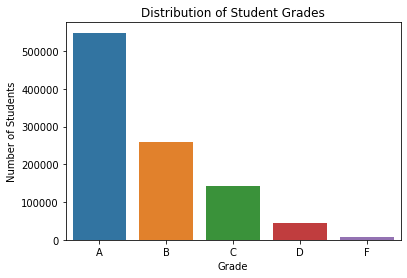

In [6]:
plt.figure(figsize=(6,4))
sns.countplot(x="grade", data=df)
plt.title("Distribution of Student Grades")
plt.xlabel("Grade")
plt.ylabel("Number of Students")
plt.show()

In [7]:
print(df.columns)

Index(['student_id', 'weekly_self_study_hours', 'attendance_percentage',
       'class_participation', 'total_score', 'grade'],
      dtype='object')


In [8]:
#PREDICT STUDENT FINAL SCORE(LINEAR REGRESSION)
X = df[['student_id', 'weekly_self_study_hours', 'attendance_percentage',
       'class_participation']]

In [9]:
Y = df['total_score']

In [10]:
X_train, X_test, Y_train, Y_test = train_test_split(
X, Y,
test_size=0.2,
random_state=42)

In [11]:
model = LinearRegression()
model.fit(X_train, Y_train)

LinearRegression()

In [12]:
pred = model.predict(X_test)

In [13]:
print("MSE:", mean_squared_error(Y_test, pred))

MSE: 80.93480435921708


In [14]:
#PREDICT PASS/FAIL(LOGISTIC REGRESSION)
df['PassFail'] = df['total_score'].apply(lambda X:1 if X>=35 else 0)

In [15]:
X = df[['student_id', 'weekly_self_study_hours', 'attendance_percentage',
       'class_participation']]

In [16]:
Y = df['PassFail']

In [17]:
X_train, X_test, Y_train, Y_test = train_test_split(
X, Y,
test_size=0.2,
random_state=42)

In [18]:
model = LogisticRegression()
model.fit(X_train, Y_train)

LogisticRegression()

In [19]:
pred = model.predict(X_test)
print(pred)

[1 1 1 ... 1 1 1]


In [20]:
#MODEL EVALUATION AND VISUALISATION
print("Accuracy:", accuracy_score(Y_test,pred ))
print("Confusion Matrix:\n", confusion_matrix(Y_test, pred))
print("Classification Report:\n", classification_report(Y_test, pred))

Accuracy: 0.9978
Confusion Matrix:
 [[     0    440]
 [     0 199560]]
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       440
           1       1.00      1.00      1.00    199560

    accuracy                           1.00    200000
   macro avg       0.50      0.50      0.50    200000
weighted avg       1.00      1.00      1.00    200000



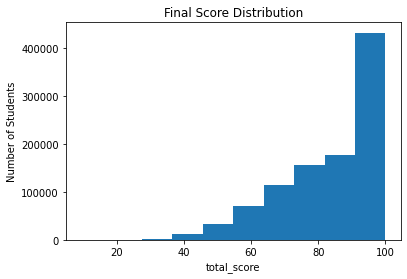

In [21]:
plt.hist(df["total_score"])
plt.title("Final Score Distribution")
plt.xlabel("total_score")
plt.ylabel("Number of Students")
plt.show()